<a href="https://colab.research.google.com/github/suzzette211/AI-For-Science-and-Engineering/blob/main/Week_5_Assignment_%7C_Building_Your_First_Supervised_Machine_Learning_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**1. Target and features**



a.   Importing and loading the data from kaggle



In [3]:
import kagglehub

path = kagglehub.dataset_download("elikplim/concrete-compressive-strength-data-set")
print("Path to dataset files:", path)

100%|██████████| 11.1k/11.1k [00:00<00:00, 6.47MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/elikplim/concrete-compressive-strength-data-set/versions/1


In [4]:
import os
import pandas as pd

print(os.listdir(path))

csv_file = [f for f in os.listdir(path) if f.endswith(".csv")][0]
df = pd.read_csv(os.path.join(path, csv_file))

print(df.shape)
df.head()

['concrete_data.csv']
(1030, 9)


,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,concrete_compressive_strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


**b. Selecting the four variables and displaying samples**

In [5]:
def find_col(keyword):
    return [c for c in df.columns if keyword.lower() in c.lower()][0]

cols = [find_col("cement"), find_col("water"), find_col("age"), find_col("compressive")]
df_sel = df[cols]

print(df_sel.isnull().sum())
df_sel.sample(5, random_state=42)

cement                           0
water                            0
age                              0
concrete_compressive_strength    0
dtype: int64


,cement,water,age,concrete_compressive_strength
31,266.0,228.0,365,52.91
109,362.6,164.9,7,55.90
136,389.9,145.9,28,74.50
88,362.6,164.9,3,35.30
918,145.0,202.0,28,10.54


**c. Target and features**

In [6]:
feature_cols = [cols[0], cols[1], cols[2]]   # cement, water, age
target_col = cols[3]                         # compressive strength

X = df_sel[feature_cols]
y = df_sel[target_col]

print("Features:", feature_cols)
print("Target:", target_col)

Features: ['cement', 'water', 'age']
Target: concrete_compressive_strength


**2. Train/test Split**

In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Train size:", X_train.shape)
print("Test size:", X_test.shape)

Train size: (824, 3)
Test size: (206, 3)


**3. Model Training( Linear regression and Random forest Regression)**

In [9]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

lin_model = LinearRegression()
lin_model.fit(X_train, y_train)

rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

4. Predictions

In [10]:
lin_pred = lin_model.predict(X_test)
rf_pred = rf_model.predict(X_test)

5. Evaluation

In [13]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def evaluate(name, y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {
        "Model": name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R²": r2_score(y_true, y_pred)
    }

results = pd.DataFrame([
    evaluate("Linear Regression", y_test, lin_pred),
    evaluate("Random Forest", y_test, rf_pred)
])
results.round(3)

,Model,MAE,MSE,RMSE,R²
0,Linear Regression,9.394,128.753,11.347,0.50
1,Random Forest,5.302,54.113,7.356,0.79


6. Actual against Predicted plot

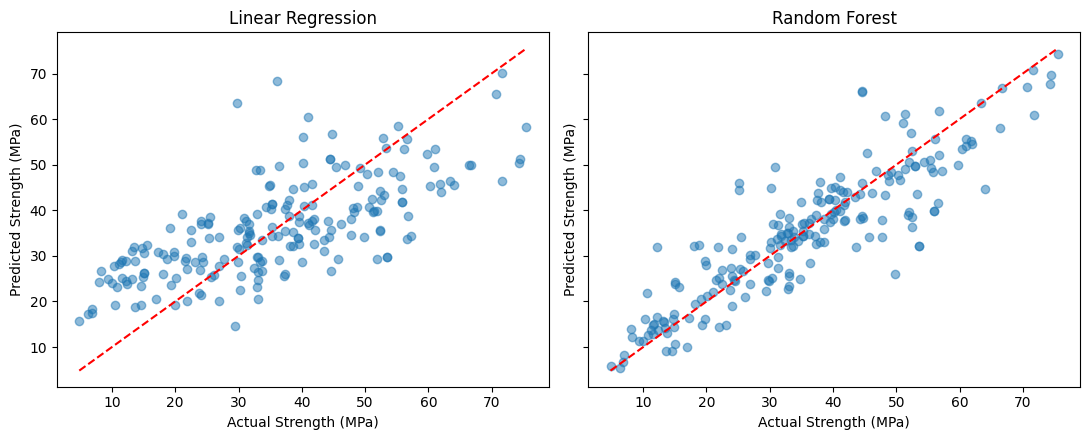

In [15]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True)

for ax, pred, name in zip(axes, [lin_pred, rf_pred], ["Linear Regression", "Random Forest"]):
    ax.scatter(y_test, pred, alpha=0.5)
    lims = [y_test.min(), y_test.max()]
    ax.plot(lims, lims, "r--")
    ax.set_title(name)
    ax.set_xlabel("Actual Strength (MPa)")
    ax.set_ylabel("Predicted Strength (MPa)")

plt.tight_layout()
plt.show()

## Supervised Learning: Concrete Compressive Strength

**Target and features**
- Target (output): concrete compressive strength (MPa)
- Features (inputs): cement (kg/m³), water (kg/m³), age (days)

**Problem type**
This is a **regression** problem because the target is a continuous numerical value
(MPa), not a set of categories.

**Method**
The data was split 80% training / 20% testing (random_state=42). Two models were trained:
1. **Linear Regression**, a simple baseline that assumes a linear relationship.
2. **Random Forest Regressor**, an ensemble of decision trees that can capture
   non-linear relationships and interactions.

**Results**
| Model | MAE | RMSE | R² |
|---|---|---|---|
| Linear Regression | 9.394| 11.347 | 0.5 |
| Random Forest | 5.302 | 7.356 | 0.79 |

**Discussion**
Random Forest achieved a lower error and a higher R² than Linear Regression. This suggests the relationship between the ingredients and strength
is not purely linear, for example strength rises quickly at early ages and then levels
off. Linear Regression is simpler and easier to interpret but cannot capture this.
Random Forest fits better but is harder to interpret and can overfit, so test-set
results are what matter.

**Limitations**
Only three features were used. Other ingredients (slag, fly ash, superplasticizer,
aggregates) also affect strength, so adding them could improve both models.